<a href="https://colab.research.google.com/github/ultimog/Econ3916-midterm/blob/main/Copy_of_Econ_3916_Midterm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 3916 Midterm Project — Econometric Foundation

**ECON 3916 · Applied Data Analytics** · Topics 1-14 · 100 points · your role: Independent analyst

This is the **starter**: the structure of the project in rubric order. Fill the empty cells and keep every heading so the grader finds each section. The brief on Canvas has the full text of every section and the rubric. The grader reruns this notebook from the top, so every number, table and figure in your report must come from a cell here.

**🛑 This project is entirely NO AI.** Not phases one to three — all of it. No AI for the code, the analysis, the writing, or the editing. This is the one assessment in the course that establishes you can do the work unaided, and it is the one you will draw on when an interviewer asks what you built. Everything you have practised with a co-pilot, you do here alone.

## Start here

Work top to bottom. What each part of this notebook is for:

1. **Data provenance**: where the file came from. It feeds Section 1 and your README.
2. **Section 1**: load the data into a DataFrame called `df`, then run the *Section 1 self-check* cell and answer the questions under it. Do this before the **Mon 2 Nov** checkpoint.
3. **Section 2**: figures, each with a caption that states a finding.
4. **Section 3**: the OLS model, with a draft committed by **Fri 6 Nov**.
5. **Section 4**: diagnostics, only after Topic 14.
6. **Section 5**: words only.
7. **Numbers my report quotes**: last. Every number in the report must be printed there.

The brief's *Six checks before you post* list the problems that came up most often in Checkpoint 1. Read them before you settle on your controls.

## Setup

Imports only. Add any others you need here, at the top.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf

## Data provenance

Fill these in when you download the data. They feed Section 1 and your README.

In [ ]:
SOURCE_URL = "https://data.imf.org/en/Data-Explorer?datasetUrn=IMF.RES:WEO(9.0.0)" # IMF World Economic Outlook, version 9.0.0
DOWNLOAD_DATE = "2026-11-02"
FILE_NAME = "imf_weo.csv"

**Who collected it, for what purpose, what is missing and why?**

*Your notes here.*

## Section 1: The Question and the Data (20 pts)

State the question in one sentence, and say why it matters and to whom. Describe the data as a product of measurement decisions, name the missingness mechanism (MCAR, MAR or MNAR) and defend the label. Build a summary-statistics table a reader can read without asking you a question.

In [ ]:
DATA_PATH = "imf_weo.csv"
FIRST, LAST = 2013, 2023     # 2013 only supplies "last year" for 2014; the models use 2014-2023

raw = pd.read_csv(DATA_PATH, low_memory=False)

# Country code and indicator code are pieces of SERIES_CODE, e.g. ESP.GGXWDG_NGDP.A
raw["iso"] = raw["SERIES_CODE"].str.extract(r"^([A-Z]{3})\.")     # the IMF's group rows (G110, GX123) become NaN
raw["code"] = raw["SERIES_CODE"].str.extract(r"\.([A-Z0-9_]+)\.")
raw = raw.dropna(subset=["iso"])

# The three indicators this project uses
keep = raw[raw["code"].isin(["GGXWDG_NGDP", "NGDPRPPPPC", "NID_NGDP"])]

# Wide to long: the year columns become one year column
years = [str(y) for y in range(FIRST, LAST + 1)]
long = keep.melt(id_vars=["iso", "code"], value_vars=years, var_name="year", value_name="value")
long["year"] = long["year"].astype(int)

# Long gives one row per country-year, one column per indicator
panel = long.pivot_table(index=["iso", "year"], columns="code", values="value", dropna=False).reset_index()
panel.columns.name = None
panel = panel.rename(columns={"GGXWDG_NGDP": "debt", "NGDPRPPPPC": "income", "NID_NGDP": "invest"})

# Last year's income and debt, put on this year's row with a merge
prev = panel[["iso", "year", "income", "debt"]].copy()
prev["year"] = prev["year"] + 1
prev = prev.rename(columns={"income": "income_prev", "debt": "debt_prev"})
panel = panel.merge(prev, on=["iso", "year"], how="left", validate="one_to_one")

panel["growth"] = (panel["income"] / panel["income_prev"] - 1) * 100   # % change in income per person
panel["log_inc_prev"] = np.log(panel["income_prev"])

df = panel[panel["year"] >= FIRST + 1]       # the analysis years, 2014-2023
main_sample = df.dropna(subset=["growth", "debt_prev", "log_inc_prev"])      # rows the main model can use
sample = main_sample.dropna(subset=["invest"])                                # the same rows, keeping only those that report investment
sample_same = main_sample.dropna(subset=["debt"])                             # rows that also have this year's debt (the same-year check)

print("Full table:", panel.shape, "| analysis years:", len(df), "country-years")
print("Main sample:", len(main_sample), "country-years from", main_sample["iso"].nunique(), "countries")
print("With investment:", len(sample), "country-years from", sample["iso"].nunique(), "countries")

Full table: (2167, 9) | analysis years: 1970 country-years
Main sample: 1901 country-years from 191 countries
With investment: 1691 country-years from 170 countries


In [ ]:
# Table 1: summary statistics for the main sample
labels = {
    "growth": "Income per person growth (%)",
    "debt_prev": "General government gross debt, previous year (% of GDP)",
    "invest": "Investment (% of GDP)",
    "income_prev": "Income per person, previous year (constant PPP $)",
}
rows = []
for col, label in labels.items():
    s = main_sample[col]
    rows.append([label, s.mean(), s.median(), s.std(), s.min(), s.max(), s.count()])
table1 = pd.DataFrame(rows, columns=["Variable (units)", "Mean", "Median", "SD", "Min", "Max", "N"]).round(2)
table1

,Variable (units),Mean,Median,SD,Min,Max,N
0,Income per person growth (%),1.56,1.90,5.22,-34.02,59.29,1901
1,"General government gross debt, previous year (...",55.04,47.49,35.73,0.05,357.45,1901
2,Investment (% of GDP),24.40,23.38,8.35,-15.68,75.92,1691
3,"Income per person, previous year (constant PPP $)",24753.38,15413.82,26118.23,829.95,175785.39,1901


In [ ]:
UNIT = "country-year"
OUTCOME = "growth"     # dependent variable's column name
MAIN_X = "debt_prev"      # explanatory variable's column name
CONTROLS = ["log_inc_prev", "invest"]    # every other column

if "df" in globals():
    print(f"Rows: {len(df):,}   Columns: {df.shape[1]}   One row is: {UNIT or '(fill in UNIT)'}")
    cols = [c for c in [OUTCOME, MAIN_X, *CONTROLS] if c]
    absent = [c for c in cols if c not in df.columns]
    if absent:
        print("Not in df:", absent)
    present = [c for c in cols if c in df.columns]
    if present:
        print("\nMissing values per column:")
        print(df[present].isna().sum().to_string())
    if OUTCOME in df.columns and pd.api.types.is_numeric_dtype(df[OUTCOME]):
        print(f"\nSkew of {OUTCOME}: {df[OUTCOME].skew():.2f} (above about 1, consider a log)")
else:
    print("Load your data into a DataFrame called df first, then run this cell.")

Rows: 1,970   Columns: 9   One row is: country-year

Missing values per column:
growth           30
debt_prev        53
log_inc_prev     30
invest          250

Skew of growth: 0.29 (above about 1, consider a log)


**Answer before you go on.**

1. For each control: does your main explanatory variable change it? If yes, it is on the path from X to Y. Drop it, or run with and without and say what each version measures.
2. Are all your variables in the same units and for the same years?
3. If your question is about a policy, where is the period before it?

*Your answers here.*

*Your words here.*

## Section 2: Descriptive Evidence (20 pts)

Show the reader the data before any model. At least two figures, each with a caption that states its finding, not its variables. Chapter 3's standards for axes. If the outcome is skewed, show it and say what you will do about it.

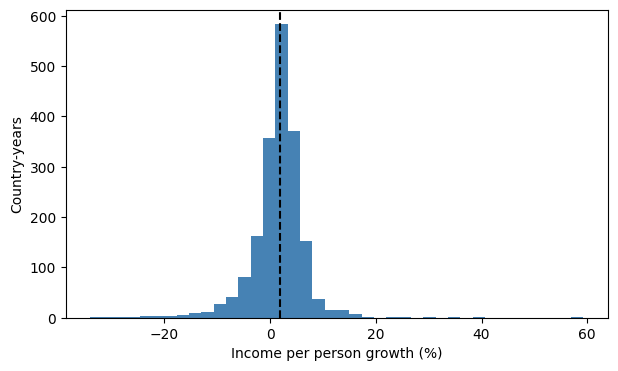

Skewness: 0.2 | median: 1.9 | mean: 1.56


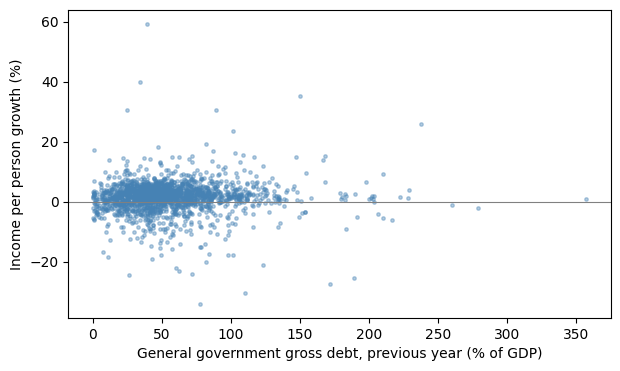

In [ ]:
# Figure 1: the outcome's distribution
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(main_sample["growth"], bins=40, color="steelblue")
ax.axvline(main_sample["growth"].median(), color="black", linestyle="--")
ax.set_xlabel("Income per person growth (%)")
ax.set_ylabel("Country-years")
plt.show()
print("Skewness:", round(main_sample["growth"].skew(), 2), "| median:", round(main_sample["growth"].median(), 2),
      "| mean:", round(main_sample["growth"].mean(), 2))

# Figure 2: debt against growth, before any controls
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(main_sample["debt_prev"], main_sample["growth"], s=6, alpha=0.4, color="steelblue")
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_xlabel("General government gross debt, previous year (% of GDP)")
ax.set_ylabel("Income per person growth (%)")
plt.show()

*Your words here.*

## Section 3: The Model (25 pts)

Fit a multivariate OLS model and report it in a formatted regression table (coefficients, standard errors, N, R-squared), not a `summary()` dump. Interpret at least two coefficients in full: magnitude, units, direction, precision. For every control, say whether it blocks a confounding path or adds precision, and what would make it a bad control (Chapter 10). OLS only: no difference-in-differences estimate.

In [ ]:
#The same country appears in many rows, so cluster the standard errors by country.
def fit(formula, data):
    return smf.ols(formula, data).fit(cov_type="cluster", cov_kwds={"groups": data["iso"]}, use_t=True)

#I made lagged debt the main model on my professor’s advice, and I left
#investment out of it because it may be on the path from debt to growth.
lagged debt is the main X (same-year debt moves mechanically with growth, because GDP is in
m1 = fit("growth ~ debt_prev + C(iso) + C(year)", main_sample)                                 # lagged debt alone
m2 = fit("growth ~ debt_prev + log_inc_prev + C(iso) + C(year)", main_sample)                  # MAIN: + last year's income
m3 = fit("growth ~ debt_prev + log_inc_prev + C(iso) + C(year)", sample)                       # main model, rows that report investment
m4 = fit("growth ~ debt_prev + log_inc_prev + invest + C(iso) + C(year)", sample)              # + investment, same rows as column 3
m5 = fit("growth ~ debt + log_inc_prev + C(iso) + C(year)", sample_same)                       # check: this year's debt instead

def regtable(models, names):
    rows = {}
    for name, m in zip(names, models):
        col = {}
        for v in ["debt", "debt_prev", "log_inc_prev", "invest"]:      # the dummies and intercept stay out of the table
            if v in m.params:
                col[v] = f"{m.params[v]:.3f}"
                col[v + " (se)"] = f"({m.bse[v]:.3f})"
        col["Country dummies"], col["Year dummies"] = "Yes", "Yes"
        col["N"], col["R2"] = f"{int(m.nobs)}", f"{m.rsquared:.2f}"
        rows[name] = col
    table = pd.DataFrame(rows).fillna("")
    order = ["debt", "debt (se)", "debt_prev", "debt_prev (se)", "log_inc_prev", "log_inc_prev (se)",
             "invest", "invest (se)", "Country dummies", "Year dummies", "N", "R2"]
    return table.reindex([r for r in order if r in table.index])      # rows in a sensible order

table_a1 = regtable([m1, m2, m3, m4, m5], ["(1) Debt only", "(2) Main", "(3) Main, rows with investment", "(4) + investment", "(5) Same-year debt"])
print(table_a1.to_string())

lo, hi = m2.conf_int().loc["debt_prev"]
print(f"\nMain model: previous-year debt coefficient {m2.params['debt_prev']:+.4f}  se {m2.bse['debt_prev']:.4f}  95% CI [{lo:+.4f}, {hi:+.4f}]  "
      f"N={int(m2.nobs)}  countries={main_sample['iso'].nunique()}")

                  (1) Debt only (2) Main (3) Main, rows with investment (4) + investment (5) Same-year debt
debt                                                                                                 -0.063
debt (se)                                                                                           (0.015)
debt_prev                 0.039    0.020                          0.037            0.041                   
debt_prev (se)          (0.018)  (0.016)                        (0.019)          (0.017)                   
log_inc_prev                      -9.116                         -8.073           -8.355            -12.923
log_inc_prev (se)                (4.918)                        (5.498)          (5.575)            (5.216)
invest                                                                             0.065                   
invest (se)                                                                      (0.028)                   
Country dummies             

*Your words here.*

## Section 4: Diagnostics (20 pts)

Residuals against fitted values and against your main predictor; a constant-variance check, with robust standard errors if it fails; variance inflation factors, interpreted; at least one influential-observation check.

**Start only after Topic 14.** Write Sections 1 to 3 first; they do not depend on it.

*Your words here.*

## Section 5: Threats and Conclusion (10 pts)

First the threats: what would have to be true for your main coefficient to be causal, is it, and if not, what your estimate is instead. Then the conclusion: what you found, how confident a reader should be, and what you would do with another month. Half a page. No new results, so there is no code cell here.

*Your words here.*

## Appendix

The regression table, the diagnostics output and any extra figures. The appendix does not count toward the 6–8 page limit of the report.

## Numbers my report quotes

Every number in your report, each with a name that says where it comes from. A number in the report that this cell does not print is unsupported, and is graded as if it were missing. Keep it the last code cell.

In [ ]:
REPORT_NUMBERS = {
    "Section 1: rows in the full table (2013-2023)": len(panel),
    "Section 1: columns in the full table": panel.shape[1],
    "Section 1: economies in the table": panel["iso"].nunique(),
    "Section 1: country-years in the analysis window (2014-2023)": len(df),
    "Section 1: missing debt in the window": int(df["debt"].isna().sum()),
    "Section 1: missing investment in the window": int(df["invest"].isna().sum()),
    "Section 1: missing income growth in the window": int(df["growth"].isna().sum()),
    "Section 1: country-years in the main sample": len(main_sample),
    "Section 1: countries in the main sample": main_sample["iso"].nunique(),
    "Section 1: country-years that also report investment": len(sample),
    "Section 3: previous-year debt coefficient, main model": round(m2.params["debt_prev"], 4),
    "Section 3: standard error, main model": round(m2.bse["debt_prev"], 4),
    "Section 3: 95% CI, main model": (round(lo, 4), round(hi, 4)),
    "Section 3: N, main model": int(m2.nobs),
    "Section 3: R-squared, main model": round(m2.rsquared, 3),
    "Section 3: coefficient on the same rows with investment excluded (column 3)": round(m3.params["debt_prev"], 4),
    "Section 3: coefficient with investment added (column 4)": round(m4.params["debt_prev"], 4),
    "Section 4: same-year debt coefficient (column 5)": round(m5.params["debt"], 4),
}

for name, value in REPORT_NUMBERS.items():
    print(f"{name}: {value}")

Section 1: rows in the full table (2013-2023): 2167
Section 1: columns in the full table: 9
Section 1: economies in the table: 197
Section 1: country-years in the analysis window (2014-2023): 1970
Section 1: missing debt in the window: 54
Section 1: missing investment in the window: 250
Section 1: missing income growth in the window: 30
Section 1: country-years in the main sample: 1901
Section 1: countries in the main sample: 191
Section 1: country-years that also report investment: 1691
Section 3: previous-year debt coefficient, main model: 0.0204
Section 3: standard error, main model: 0.0157
Section 3: 95% CI, main model: (-0.0106, 0.0514)
Section 3: N, main model: 1901
Section 3: R-squared, main model: 0.464
Section 3: coefficient on the same rows with investment excluded (column 3): 0.037
Section 3: coefficient with investment added (column 4): 0.0413
Section 4: same-year debt coefficient (column 5): -0.0631


## Checkpoints

In Colab, *File › Save a copy in GitHub* makes a commit each time you use it. Save at each checkpoint so the commit history shows it.

- [ ] **Mon 26 Oct:** your question and data source, posted in the Midterm checkpoint 1 discussion.
- [ ] **Mon 2 Nov:** your data loaded and your summary table, committed to your repository.
- [ ] **Fri 6 Nov:** a draft of your model, committed.
- [ ] **Mon 9 Nov, 11:59pm:** the project is due.

## Before you submit

- [ ] A Colab notebook with all your analysis, cleanly organised.
- [ ] A written report, 6 to 8 pages of text, uploaded as a PDF.
- [ ] A GitHub repository containing both, with a `README.md` you wrote yourself.
- [ ] **Question and data provenance (20):** A defensible measurable question; data described as a measurement product; missingness mechanism identified and defended; interpretable summary table
- [ ] **Descriptive evidence (20):** Two or more figures each making a stated point; captions state findings not variables; Chapter 3 standards met
- [ ] **Model and interpretation (25):** Properly formatted regression table; two coefficients interpreted in full including units and magnitude; every control justified by role
- [ ] **Diagnostics (20):** Residuals, heteroskedasticity, VIF and influence all run and interpreted; robust errors used where warranted
- [ ] **Threats and conclusion (10):** The causal claim assessed in plain terms; the estimand correctly labelled if not causal; conclusion adds no new results
- [ ] **Repository, checkpoints and reproducibility (5):** Public GitHub repo containing the notebook and the report; the two committed checkpoints visible in the commit history; data included or its download documented; a self-written README giving the question, the source, how to run it and the headline finding
- [ ] The Colab notebook is shared with *Anyone with the link*, and the link is in the Canvas submission box.
- [ ] Every number in the report is printed by the *Numbers my report quotes* cell.
- [ ] No AI anywhere: code, analysis, writing, editing, README.
- [ ] *File › Save a copy in GitHub*, path `Midterm Project/Econ_3916_Midterm.ipynb`.
- [ ] Run *Runtime › Restart and run all* once, top to bottom, before you hand in.